# Clasificación de 3 escenas: ML, CNN, DenseNet y Transformers

Comparamos nueve modelos sobre el dataset de 3 escenas (`coast`, `forest`,
`highway`; 958 imágenes), todos con el mismo split y las mismas métricas. Cada
modelo se entrena en su cuaderno y guarda sus resultados en `resultados/`; este
cuaderno los reúne y los compara.

| Familia | Modelo | Cuaderno |
|---|---|---|
| CNN | CNN base, mejorada v1 y mejorada v2 | `ScenesCNN.ipynb` |
| DL no secuencial | DenseNet121 preentrenada + fine-tuning | `ScenesDenseNet.ipynb` |
| Transformer | ViT entrenado desde cero | `ScenesViT.ipynb` |
| Transformer | ViT-B/16 preentrenado + fine-tuning | `ScenesViTPretrained.ipynb` |
| Machine learning | Regresión logística, SVM y Random Forest (HSV + HOG) | `ScenesClassicML.ipynb` |

## Protocolo

* **Split** estratificado con semilla 20: 610 train, 108 validación y 240 test
  (`resultados/split.json`). El test solo se usa para evaluar.
* **Métricas**: accuracy, precisión, recall y F1 (macro y weighted), kappa de
  Cohen, ROC-AUC one-vs-rest y matriz de confusión.
* **Validación estadística**: IC 95 % de la accuracy por bootstrap (2000
  remuestreos) y test exacto de McNemar entre pares de modelos.

## Tabla resumen

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

import common_3scenes as cs

sns.set_theme(style="whitegrid", context="notebook")
comparison_dir = cs.result_dir("comparacion")
comparison_dir.mkdir(parents=True, exist_ok=True)

order = [
    "cnn/base",
    "cnn/mejorada",
    "cnn/mejorada_v2",
    "densenet",
    "vit",
    "vit_preentrenado",
    "ml/logreg",
    "ml/svm",
    "ml/rf",
]
FAMILY_COLORS = {
    "CNN": "#4C72B0",
    "DL (non-sequential)": "#55A868",
    "IA generativa (Transformer)": "#C44E52",
    "machine learning": "#8172B2",
}
FAMILY_LABELS = {
    "CNN": "CNN",
    "DL (non-sequential)": "DL no secuencial",
    "IA generativa (Transformer)": "Transformer",
    "machine learning": "Machine learning",
}
GUIDE2_BEST = 0.9000  # Random Forest, RGB + HSV + Haralick (guia-2/reto-5)
GUIDE2_BASELINE = 0.8125  # MLP with RGB means/stds (guia-2/reto-5)

results = cs.load_all_results()
split_meta = cs.load_split()
results["order"] = results["folder"].map({folder: i for i, folder in enumerate(order)})
results = results.sort_values("order").drop(columns="order").reset_index(drop=True)

predictions = {}
intervals = []
for _, row in results.iterrows():
    frame = cs.load_predictions(row["folder"])
    predictions[row["model"]] = frame
    intervals.append(
        cs.bootstrap_accuracy_ci(frame["true_class"], frame["predicted_class"], n_boot=2000)
    )
results["accuracy_low"], results["accuracy_high"] = zip(*intervals)

summary_columns = [
    "model", "family", "accuracy", "f1_macro", "f1_weighted", "precision_macro",
    "recall_macro", "cohen_kappa", "roc_auc_ovr_macro", "parameters",
    "training_seconds", "inference_ms_per_image", "epochs",
]
summary = results[summary_columns].copy()
summary.to_csv(comparison_dir / "model_summary.csv", index=False)

display_summary = summary.rename(
    columns={
        "model": "Modelo",
        "family": "Familia",
        "accuracy": "Accuracy",
        "f1_macro": "F1 macro",
        "f1_weighted": "F1 weighted",
        "precision_macro": "Precisión macro",
        "recall_macro": "Recall macro",
        "cohen_kappa": "Kappa",
        "roc_auc_ovr_macro": "AUC OVR",
        "parameters": "Parámetros",
        "training_seconds": "Entrenamiento (s)",
        "inference_ms_per_image": "Inferencia (ms/img)",
        "epochs": "Épocas",
    }
)
display_summary["Familia"] = display_summary["Familia"].map(FAMILY_LABELS)
display_summary["Parámetros"] = display_summary["Parámetros"].map(
    lambda value: "—" if pd.isna(value) else f"{int(value):,}"
)
display_summary["Entrenamiento (s)"] = display_summary["Entrenamiento (s)"].map(lambda value: f"{value:,.0f}")
display_summary["Inferencia (ms/img)"] = display_summary["Inferencia (ms/img)"].map(lambda value: f"{value:.1f}")
display_summary["Épocas"] = display_summary["Épocas"].map(
    lambda value: "—" if pd.isna(value) else f"{int(value)}"
)
print(f"{len(results)} modelos | test común: {split_meta['n_test']} imágenes")
display_summary.round(4)

9 modelos | test común: 240 imágenes


,Modelo,Familia,Accuracy,F1 macro,F1 weighted,Precisión macro,Recall macro,Kappa,AUC OVR,Parámetros,Entrenamiento (s),Inferencia (ms/img),Épocas
0,CNN base,CNN,0.9042,0.9012,0.9035,0.9006,0.9025,0.8554,0.9767,"30,611",7,1.2,15
1,CNN mejorada,CNN,0.8708,0.8608,0.8661,0.8916,0.8553,0.8026,0.9668,"305,251",482,5.1,40
2,CNN mejorada v2,CNN,0.8917,0.8850,0.8890,0.9003,0.8806,0.8351,0.9782,"305,251",963,9.9,51
3,DenseNet121,DL no secuencial,0.9833,0.9836,0.9833,0.9847,0.9828,0.9748,0.9963,"7,040,579",128,15.9,23
4,ViT (desde cero),Transformer,0.8875,0.8855,0.8864,0.8861,0.8873,0.8303,0.9629,"4,855,299","2,345",35.1,51
5,ViT preentrenado (ImageNet),Transformer,0.9750,0.9757,0.9749,0.9748,0.9774,0.9623,0.9980,"85,800,963","1,212",120.9,12
6,Regresión logística,Machine learning,0.9417,0.9391,0.9408,0.9450,0.9362,0.9116,0.9836,—,0,0.0,—
7,SVM (RBF),Machine learning,0.9542,0.9526,0.9537,0.9579,0.9497,0.9306,0.9883,—,0,0.4,—
8,Random Forest,Machine learning,0.9333,0.9300,0.9323,0.9355,0.9276,0.8990,0.9874,—,2,0.1,—


## Figura 1: accuracy con IC 95 %

Modelos ordenados por accuracy y coloreados por familia. Las líneas discontinuas
marcan el mejor resultado de la guía 2 y su línea base.

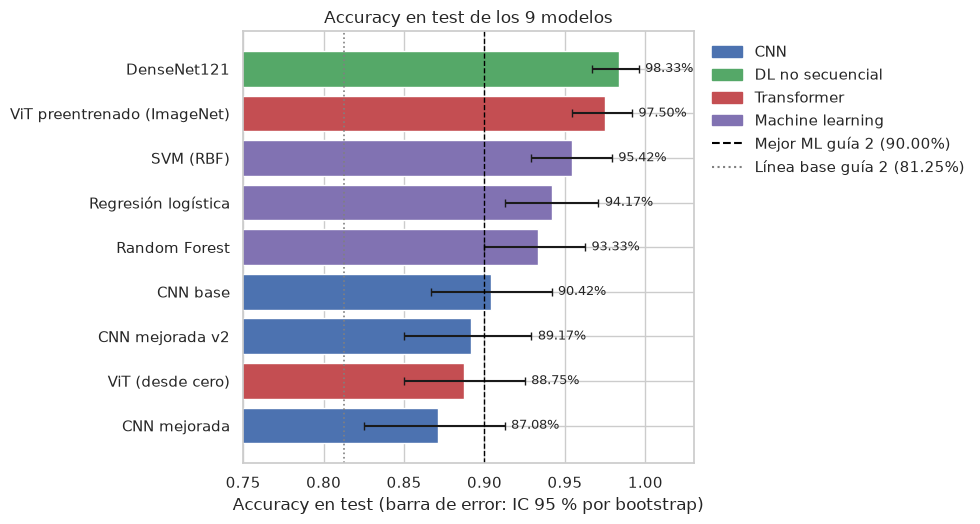

In [2]:
ranked = results.sort_values("accuracy").reset_index(drop=True)
fig, ax = plt.subplots(figsize=(10, 5.4))
ax.barh(
    ranked["model"],
    ranked["accuracy"],
    xerr=[ranked["accuracy"] - ranked["accuracy_low"], ranked["accuracy_high"] - ranked["accuracy"]],
    color=ranked["family"].map(FAMILY_COLORS),
    capsize=3,
)
for position, row in ranked.iterrows():
    ax.text(row["accuracy_high"] + 0.004, position, f"{row['accuracy']:.2%}", va="center", fontsize=9)
ax.axvline(GUIDE2_BEST, color="black", linestyle="--", linewidth=1)
ax.axvline(GUIDE2_BASELINE, color="gray", linestyle=":", linewidth=1.2)
handles = [Patch(color=color, label=FAMILY_LABELS[family]) for family, color in FAMILY_COLORS.items()]
handles += [
    Line2D([0], [0], color="black", linestyle="--", label=f"Mejor ML guía 2 ({GUIDE2_BEST:.2%})"),
    Line2D([0], [0], color="gray", linestyle=":", label=f"Línea base guía 2 ({GUIDE2_BASELINE:.2%})"),
]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
ax.set_xlim(0.75, 1.03)
ax.set_xlabel("Accuracy en test (barra de error: IC 95 % por bootstrap)")
ax.set_title("Accuracy en test de los 9 modelos")
fig.tight_layout()
fig.savefig(comparison_dir / "barras_accuracy_ic95.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 2: matrices de confusión

Normalizadas por fila: la diagonal es el recall de cada clase.

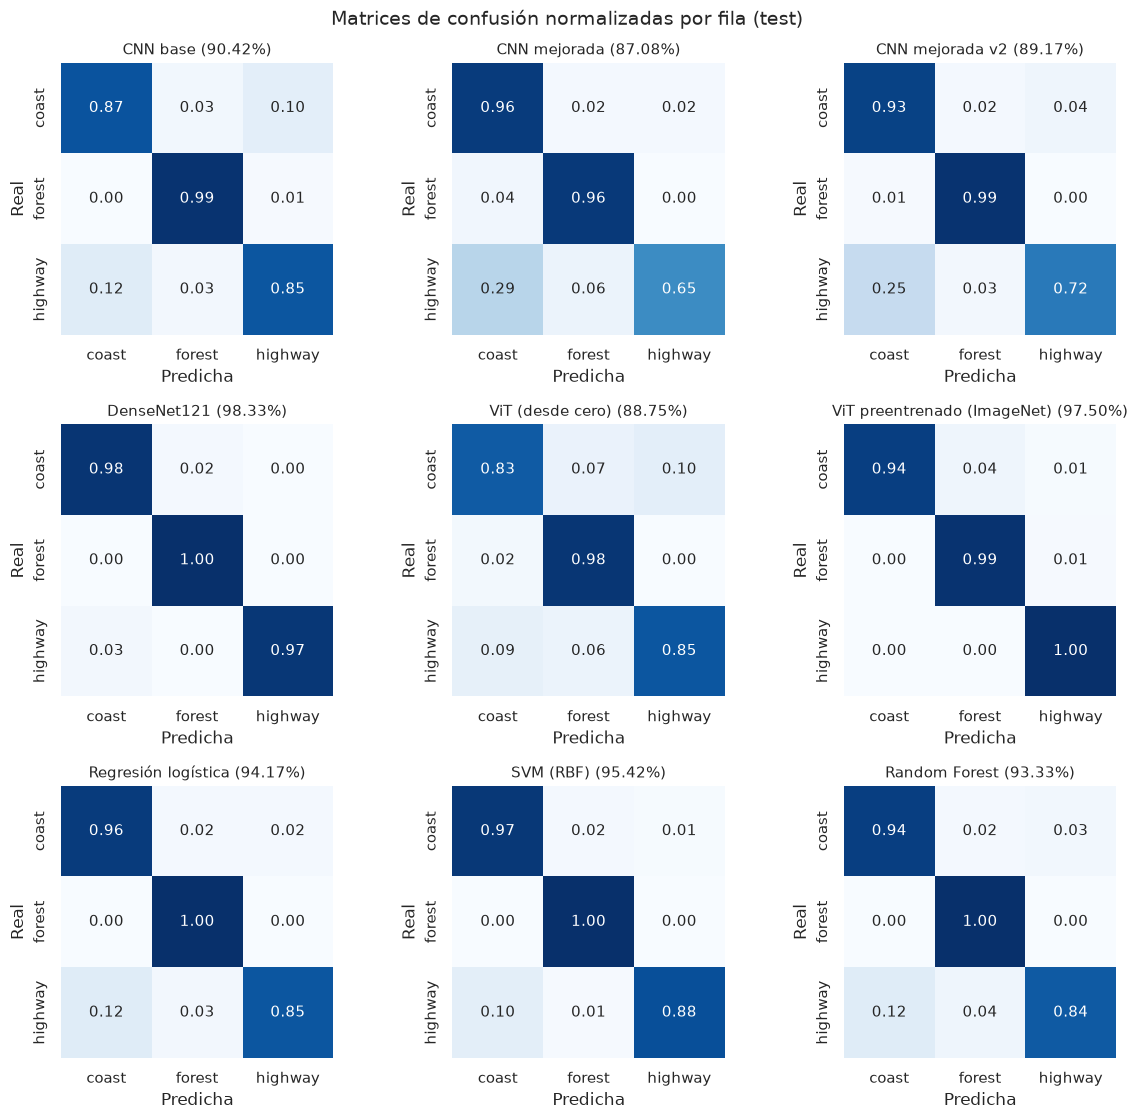

In [3]:
columns = 3
rows = int(np.ceil(len(results) / columns))
fig, axes = plt.subplots(rows, columns, figsize=(12, 3.8 * rows))
for ax, (_, row) in zip(axes.flat, results.iterrows()):
    matrix = np.asarray(cs.load_metrics(row["folder"])["confusion_matrix"], dtype=float)
    matrix = matrix / matrix.sum(axis=1, keepdims=True)
    sns.heatmap(
        matrix,
        annot=True,
        fmt=".2f",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        square=True,
        xticklabels=cs.CLASSES,
        yticklabels=cs.CLASSES,
        annot_kws={"size": 11},
        ax=ax,
    )
    ax.set_title(f"{row['model']} ({row['accuracy']:.2%})", fontsize=11)
    ax.set_xlabel("Predicha")
    ax.set_ylabel("Real")
for ax in axes.flat[len(results):]:
    ax.axis("off")
fig.suptitle("Matrices de confusión normalizadas por fila (test)", fontsize=14)
fig.tight_layout()
fig.savefig(comparison_dir / "matrices_confusion.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 3: curvas de aprendizaje

Accuracy y pérdida por época de los modelos que se entrenan por épocas (los
modelos clásicos no tienen curvas).

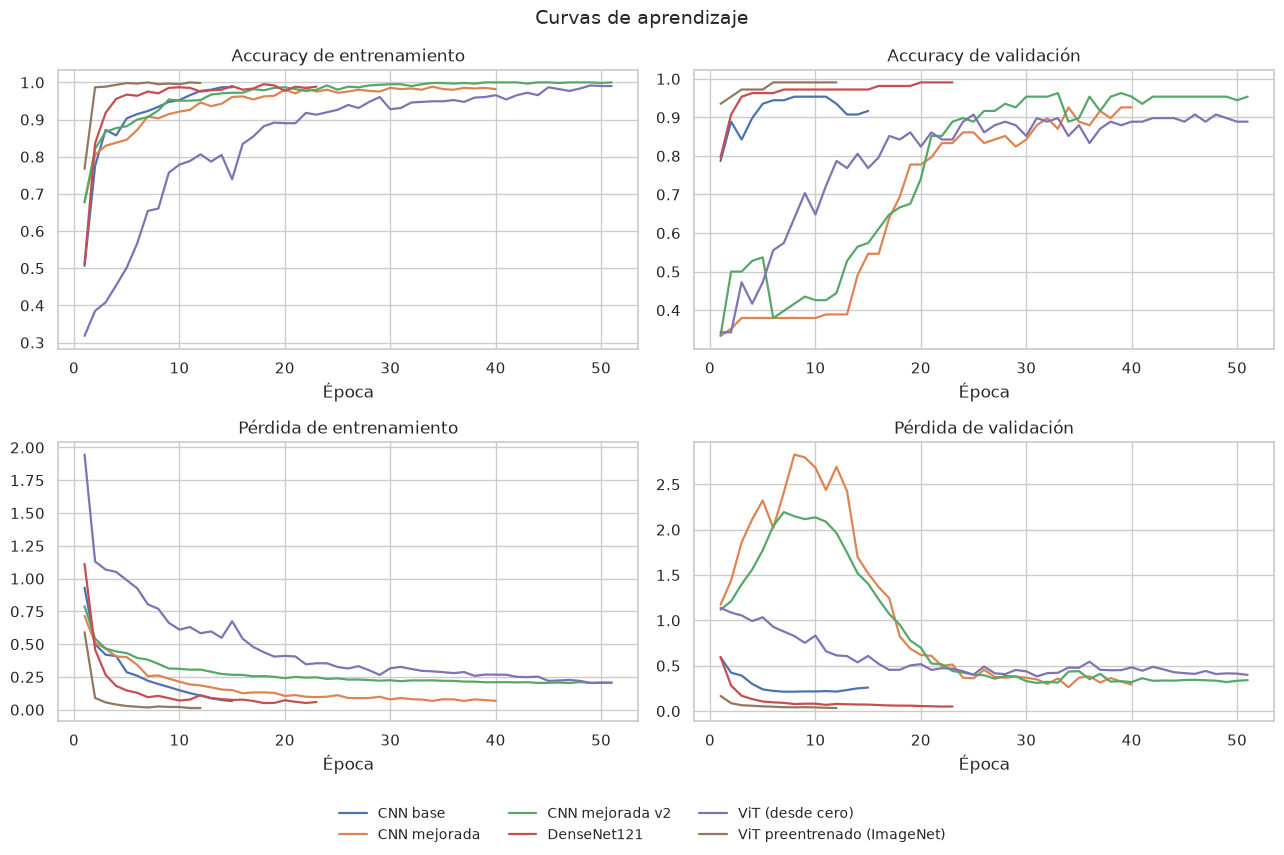

In [4]:
fig, axes = plt.subplots(2, 2, figsize=(13, 8.6))
curves = [
    ("accuracy", "Accuracy de entrenamiento", axes[0, 0]),
    ("val_accuracy", "Accuracy de validación", axes[0, 1]),
    ("loss", "Pérdida de entrenamiento", axes[1, 0]),
    ("val_loss", "Pérdida de validación", axes[1, 1]),
]
for _, row in results.iterrows():
    history = cs.load_history(row["folder"])
    if history is None:
        continue
    for column, _, ax in curves:
        ax.plot(history.index, history[column], label=row["model"], linewidth=1.6)
for column, title, ax in curves:
    ax.set_xlabel("Época")
    ax.set_title(title)
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(handles, labels, loc="lower center", ncol=3, frameon=False, fontsize=10)
fig.suptitle("Curvas de aprendizaje", fontsize=14)
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(comparison_dir / "curvas_aprendizaje.png", dpi=150, bbox_inches="tight")
plt.show()

## Figura 4: F1 por clase

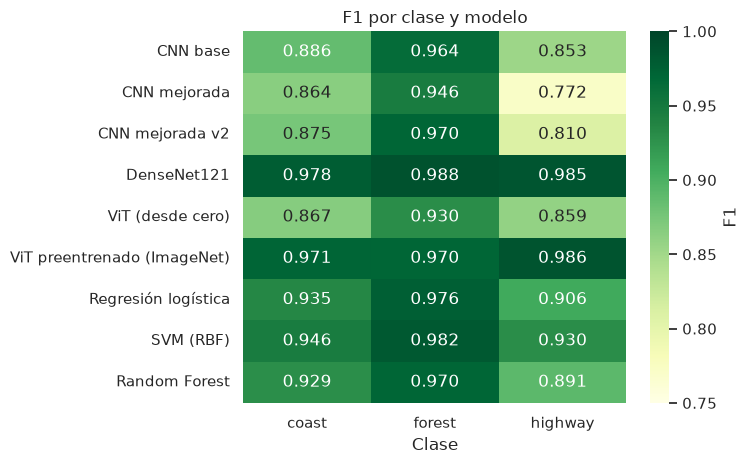

In [5]:
f1_matrix = results.set_index("model")[[f"f1_{name}" for name in cs.CLASSES]]
f1_matrix.columns = cs.CLASSES
fig, ax = plt.subplots(figsize=(7.5, 4.8))
sns.heatmap(f1_matrix, annot=True, fmt=".3f", cmap="YlGn", vmin=0.75, vmax=1, ax=ax, cbar_kws={"label": "F1"})
ax.set_title("F1 por clase y modelo")
ax.set_xlabel("Clase")
ax.set_ylabel("")
fig.tight_layout()
fig.savefig(comparison_dir / "heatmap_f1_por_clase.png", dpi=150, bbox_inches="tight")
plt.show()

## Test de McNemar

Compara los aciertos de dos modelos imagen por imagen sobre el mismo test
(α = 0.05). Se guarda en `resultados/comparacion/mcnemar_pvalues.csv`.

In [6]:
def model_of(folder):
    return results.loc[results["folder"] == folder, "model"].iloc[0]


def accuracy_of(folder):
    return results.loc[results["folder"] == folder, "accuracy"].iloc[0]


def pvalue_of(folder_a, folder_b):
    frame_a, frame_b = predictions[model_of(folder_a)], predictions[model_of(folder_b)]
    return cs.mcnemar_pvalue(frame_a["true_class"], frame_a["predicted_class"], frame_b["predicted_class"])


best_ml = results[results["folder"].str.startswith("ml/")].sort_values("accuracy").iloc[-1]
best_dl = results[~results["folder"].str.startswith("ml/")].sort_values("accuracy").iloc[-1]
comparison_pairs = [
    ("cnn/base", "cnn/mejorada"),
    ("cnn/mejorada", "densenet"),
    ("cnn/base", "densenet"),
    ("cnn/mejorada_v2", "cnn/base"),
    ("cnn/mejorada_v2", "cnn/mejorada"),
    ("cnn/mejorada_v2", "densenet"),
    ("vit", "cnn/mejorada_v2"),
    ("vit", "densenet"),
    ("vit_preentrenado", "vit"),
    ("vit_preentrenado", "densenet"),
    (best_ml["folder"], best_dl["folder"]),
]
mcnemar_table = pd.DataFrame(
    [
        {"modelo_a": model_of(a), "modelo_b": model_of(b), "p_valor": pvalue_of(a, b)}
        for a, b in comparison_pairs
    ]
)
mcnemar_table.to_csv(comparison_dir / "mcnemar_pvalues.csv", float_format="%.4f", index=False)
mcnemar_table["veredicto"] = np.where(mcnemar_table["p_valor"] < 0.05, "significativa", "no significativa")
mcnemar_table.round(4)

,modelo_a,modelo_b,p_valor,veredicto
0,CNN base,CNN mejorada,0.2005,no significativa
1,CNN mejorada,DenseNet121,0.0000,significativa
2,CNN base,DenseNet121,0.0001,significativa
3,CNN mejorada v2,CNN base,0.7011,no significativa
4,CNN mejorada v2,CNN mejorada,0.2668,no significativa
5,CNN mejorada v2,DenseNet121,0.0000,significativa
6,ViT (desde cero),CNN mejorada v2,1.0000,no significativa
7,ViT (desde cero),DenseNet121,0.0000,significativa
8,ViT preentrenado (ImageNet),ViT (desde cero),0.0001,significativa
9,ViT preentrenado (ImageNet),DenseNet121,0.6875,no significativa


## Transformers: arquitectura frente a preentrenamiento

Con los dos ViT separamos los dos efectos: el ViT desde cero frente a la CNN v2
compara arquitecturas sin preentrenamiento, y el ViT preentrenado frente a
DenseNet121 las compara con ImageNet.

In [7]:
checks = [
    ("Arquitectura, desde cero", "cnn/mejorada_v2", "vit"),
    ("Preentrenamiento, mismo ViT", "vit", "vit_preentrenado"),
    ("Arquitectura, con ImageNet", "densenet", "vit_preentrenado"),
]
pd.DataFrame(
    [
        {
            "Comparación": question,
            "Modelo A": model_of(a),
            "Modelo B": model_of(b),
            "B − A (puntos)": round(100 * (accuracy_of(b) - accuracy_of(a)), 2),
            "p McNemar": round(pvalue_of(a, b), 4),
            "Veredicto": "significativa" if pvalue_of(a, b) < 0.05 else "no significativa",
        }
        for question, a, b in checks
    ]
)

,Comparación,Modelo A,Modelo B,B − A (puntos),p McNemar,Veredicto
0,"Arquitectura, desde cero",CNN mejorada v2,ViT (desde cero),-0.42,1.0000,no significativa
1,"Preentrenamiento, mismo ViT",ViT (desde cero),ViT preentrenado (ImageNet),8.75,0.0001,significativa
2,"Arquitectura, con ImageNet",DenseNet121,ViT preentrenado (ImageNet),-0.83,0.6875,no significativa


## Comparación con el machine learning de la guía 2

Resultados de `guia-2/reto-5/reto-5.ipynb` (descriptores RGB + HSV + Haralick,
25 características). Ese cuaderno usa el mismo protocolo (25 % de test,
semilla 20), pero no garantiza las mismas 240 imágenes de test, así que esta
comparación es orientativa y no entra en el McNemar.

| Modelo (guía 2) | Accuracy CV (5 pliegues) | Accuracy test |
|---|---|---|
| Random Forest | 90.11 % | **90.00 %** |
| MLP | 90.67 % | 89.17 % |
| SVC (RBF) | **90.81 %** | 88.75 % |
| Regresión logística | 89.70 % | 88.75 % |
| Stacking (KNN + SVC + RF) | 90.25 % | 88.33 % |
| KNN | 86.63 % | 83.33 % |
| Árbol de decisión | 81.20 % | 82.08 % |
| Bayes gaussiano | 80.92 % | 77.50 % |
| K-means (K = 3) | — | 66.39 % |
| MLP línea base (medias y desv. RGB) | — | 81.25 % |

**Todos los modelos, ordenados por accuracy en test:**

| Familia | Modelo | Características | Accuracy test |
|---|---|---|---|
| DL no secuencial | DenseNet121 (ImageNet + fine-tuning) | aprendidas | **98.33 %** |
| Transformer | ViT-B/16 preentrenado | aprendidas | 97.50 % |
| ML (este reto) | SVM (RBF) | HSV + HOG | 95.42 % |
| ML (este reto) | Regresión logística | HSV + HOG | 94.17 % |
| ML (este reto) | Random Forest | HSV + HOG | 93.33 % |
| CNN | CNN base | aprendidas | 90.42 % |
| ML (guía 2) | Random Forest | RGB + HSV + Haralick | 90.00 % |
| CNN | CNN mejorada v2 | aprendidas | 89.17 % |
| Transformer | ViT desde cero | aprendidas | 88.75 % |
| ML (guía 2) | SVC (RBF) | RGB + HSV + Haralick | 88.75 % |
| CNN | CNN mejorada v1 | aprendidas | 87.08 % |
| ML (guía 2) | MLP línea base | medias/desv. RGB | 81.25 % |

## Conclusiones

1. **El mejor modelo es DenseNet121 (98.33 %).** El ViT preentrenado queda a
   0.8 puntos (97.50 %) y McNemar no los separa (p = 0.6875).
2. **Lo que más pesa es el preentrenamiento.** Las cuatro redes entrenadas desde
   cero (CNN base, v1, v2 y ViT) quedan entre 87 % y 90 % y no se distinguen
   entre sí. Partir de ImageNet sube el ViT 8.75 puntos (p = 0.0001).
3. **Mejorar la CNN no subió la accuracy.** La v1 perdió 3.3 puntos frente a la
   base y la v2 los recuperó hasta 89.17 %, sin diferencia significativa con la
   base (p = 0.7011). Con 610 imágenes, el límite lo ponen los datos.
4. **El ML clásico sigue siendo competitivo.** El SVM con HSV + HOG (95.42 %)
   supera a todas las redes entrenadas desde cero y no se distingue
   estadísticamente de DenseNet121 (p = 0.0654). Frente a la guía 2 (90.00 %),
   la mejora viene de añadir HOG.
5. **La atención no supera a la convolución en este dataset.** Desde cero, el
   ViT empata con la CNN v2 (p = 1.0000); con ImageNet, empata con
   DenseNet121. Además es el modelo más costoso: 86 M de parámetros y 121 ms
   por imagen, frente a 7 M y 16 ms de DenseNet121.